# Single point calculation

量子ダイナミクスのためにはエネルギーや勾配を計算するPotentialが必要である。

PySCIVRは以下のようなPotentialをサポートしている。(詳しくは https://tsumura-m.github.io/PySCIVR/pyscivr.potentials.html)

- `ASEPotential`: [ASE](https://ase.gitlab.io/ase/)のCalculatorをPySCIVR用にラッパーしたもの。ASEがサポートしている量子計算ソフトウェアやMACEのようなNeural Network potentialを用いることができる。
- `DFTPotential`: [PySCF](https://pyscf.org/)でDFTのエネルギーと勾配を返す。
- `ZeroPotential`: いかなる構造に対しても0を返す。純回転などポテンシャルエネルギーの計算を必要としない計算で用いる。
- `H2SplinePotential`: スプライン補間(CCSD(T)/aug-cc-pV5Z 0.4~1.5 ang spacing 0.02)により得られた水素の解析的なポテンシャル。

以下ではいくつかについて使用例を示す。

### H2SpinePotential

特段用意を必要としない。

まず、PySCIVRでは[ASE](https://ase.gitlab.io/ase/)と同様に、長さの単位に$\AA$を、エネルギーの単位にeVを用いる。(詳しくは https://tsumura-m.github.io/PySCIVR/pyscivr.units.html)

inputの構造は$\AA$で渡し、outputについてはエネルギーの単位がeV、勾配がeV/$\AA$であることに注意せよ。

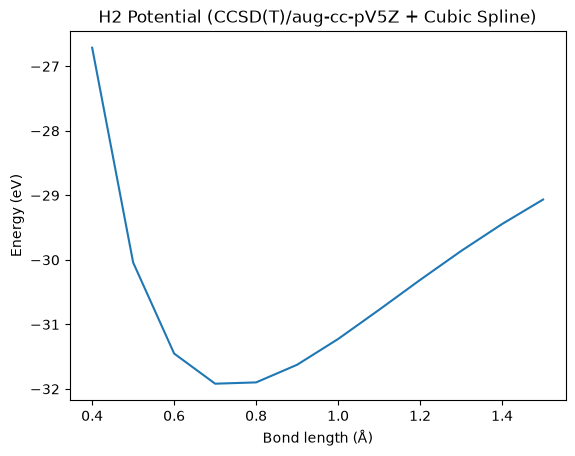

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import H2SplinePotential

pot_h2 = H2SplinePotential()

ener_list = []
r_list = np.linspace(0.4, 1.5, 12)

for r in r_list:
    posi = np.array([[0.0, 0.0, 0.0], [0.0, 0.0, r]])
    ener, forces = pot_h2.energy_forces(posi)
    ener_list.append(ener)

plt.xlabel("Bond length (Å)")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (CCSD(T)/aug-cc-pV5Z + Cubic Spline)")
plt.plot(r_list, ener_list)
plt.show()

バッチ処理にも対応している。ASEPotentialでも複数の構造をバッチとして渡せるが内部ではsequentialに処理していることに注意。

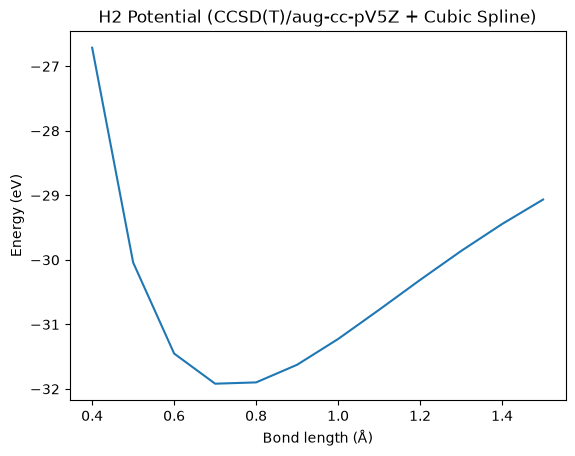

In [2]:
posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])
ener_list_batch, _ = pot_h2.energy_forces(posi_list)

plt.xlabel("Bond length (Å)")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (CCSD(T)/aug-cc-pV5Z + Cubic Spline)")
plt.plot(r_list, ener_list_batch)
plt.show()

### ASEPotential with MACE-ANI-CC

ここではニューラルネットワークポテンシャルのMACE-ANI-CCモデルを用いる。
実行するためにはaseとmace関連のモジュールをインストールする必要があり以下でできる。

```bash
uv sync --extra ase
```

ここではMACEモデルをCPU上にロードして用いる。

Reference : 

D. P. Kovács, I. Batatia, E. S. Arany, and G. Csányi, “Evaluation of the MACE force field architecture: From medicinal chemistry to materials science,” The Journal of Chemical Physics 159,
044118 (2023).

/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using ANI couple cluster model for MACECalculator, see https://doi.org/10.1063/5.0155322


/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)
/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/Users/masaya/Desktop/boxes/pyscivr/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


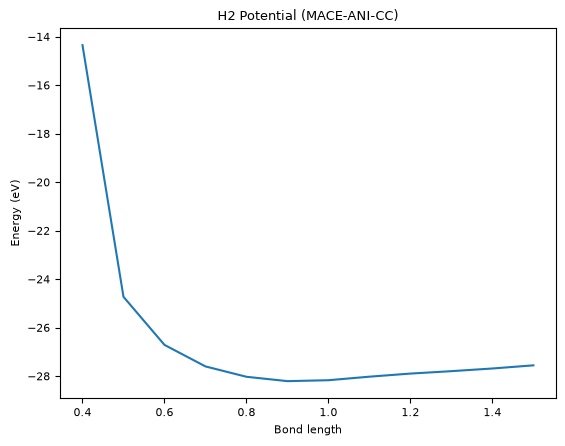

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import mace_anicc_potential

pot_mace = mace_anicc_potential(['H', 'H'], device='cpu', num_threads=1)
r_list = np.linspace(0.4, 1.5, 12)
posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])

ener_list_batch, _ = pot_mace.energy_forces(posi_list)

plt.xlabel("Bond length")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (MACE-ANI-CC)")
plt.plot(r_list, ener_list_batch)
plt.show()